In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [ ]:
#### INPUT PATH AND LOAD DATA
INPUT_FOLDER = 'tris\\force_dist_v4'
r0_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 14]

# Create a dictionary to store all dataframes
K35_dfs = {}

# Load data for each r0 value
for r0 in r0_values:
    # Construct the path
    path = os.path.join(INPUT_FOLDER, f'K_035_r0_{r0}\\obs.dat')
    
    # Load the dataframe
    K35_dfs[r0] = pd.read_csv(path, 
                              delim_whitespace=True, 
                              header=None,
                              names=['step','dist','force_mag','hbond'])

# Create individual variables
K35_r0_2_df = K35_dfs[2]
K35_r0_3_df = K35_dfs[3]
K35_r0_4_df = K35_dfs[4]
K35_r0_5_df = K35_dfs[5]
K35_r0_6_df = K35_dfs[6]
K35_r0_7_df = K35_dfs[7]
K35_r0_8_df = K35_dfs[8]
K35_r0_9_df = K35_dfs[9]
K35_r0_10_df = K35_dfs[10]
K35_r0_12_df = K35_dfs[12]
K35_r0_14_df = K35_dfs[14]

C:\Users\Tristan\AppData\Local\Temp\ipykernel_32868\1033380523.py:14: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  K35_dfs[r0] = pd.read_csv(path,
C:\Users\Tristan\AppData\Local\Temp\ipykernel_32868\1033380523.py:14: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  K35_dfs[r0] = pd.read_csv(path,
C:\Users\Tristan\AppData\Local\Temp\ipykernel_32868\1033380523.py:14: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  K35_dfs[r0] = pd.read_csv(path,
C:\Users\Tristan\AppData\Local\Temp\ipykernel_32868\1033380523.py:14: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  K35_dfs[r0] = pd.read_csv(path,
C:\Users\Tristan

In [ ]:
#### FILTER DATA
from functions import *

WINDOW_SIZE = 1  # Adjust to control smoothing

# Create a dictionary to store all filtered dataframes
K35_dfs_filtered = {}

# Apply moving average filter to each dataframe
for r0 in r0_values:
    K35_dfs_filtered[r0] = moving_average_filter(K35_dfs[r0], 
                                                  window_size=WINDOW_SIZE, 
                                                  epoch_col='step', 
                                                  filter_cols='force_mag')

# Create individual variables
K35_r0_2_df_filtered = K35_dfs_filtered[2]
K35_r0_3_df_filtered = K35_dfs_filtered[3]
K35_r0_4_df_filtered = K35_dfs_filtered[4]
K35_r0_5_df_filtered = K35_dfs_filtered[5]
K35_r0_6_df_filtered = K35_dfs_filtered[6]
K35_r0_7_df_filtered = K35_dfs_filtered[7]
K35_r0_8_df_filtered = K35_dfs_filtered[8]
K35_r0_9_df_filtered = K35_dfs_filtered[9]
K35_r0_10_df_filtered = K35_dfs_filtered[10]
K35_r0_12_df_filtered = K35_dfs_filtered[12]
K35_r0_14_df_filtered = K35_dfs_filtered[14]

In [49]:
#### APPLY CUTOFF
CUTOFF = 0.25e7  # 2,500,000 steps

# Create a dictionary to store all cutoff-filtered dataframes
K35_dfs_cfiltered = {}

# Apply cutoff filter to each dataframe
for r0 in r0_values:
    K35_dfs_cfiltered[r0] = K35_dfs_filtered[r0][K35_dfs_filtered[r0]['step'] >= CUTOFF].reset_index(drop=True)

# Create individual variables
K35_r0_2_df_cfiltered = K35_dfs_cfiltered[2]
K35_r0_3_df_cfiltered = K35_dfs_cfiltered[3]
K35_r0_4_df_cfiltered = K35_dfs_cfiltered[4]
K35_r0_5_df_cfiltered = K35_dfs_cfiltered[5]
K35_r0_6_df_cfiltered = K35_dfs_cfiltered[6]
K35_r0_7_df_cfiltered = K35_dfs_cfiltered[7]
K35_r0_8_df_cfiltered = K35_dfs_cfiltered[8]
K35_r0_9_df_cfiltered = K35_dfs_cfiltered[9]
K35_r0_10_df_cfiltered = K35_dfs_cfiltered[10]
K35_r0_12_df_cfiltered = K35_dfs_cfiltered[12]
K35_r0_14_df_cfiltered = K35_dfs_cfiltered[14]

In [50]:
#### BASIC STATISTICS OF STEADY STATE REGION
r0_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 14]

# Map r0 values to their corresponding dataframes
df_dict = {
    2: K35_r0_2_df_cfiltered,
    3: K35_r0_3_df_cfiltered,
    4: K35_r0_4_df_cfiltered,
    5: K35_r0_5_df_cfiltered,
    6: K35_r0_6_df_cfiltered,
    7: K35_r0_7_df_cfiltered,
    8: K35_r0_8_df_cfiltered,
    9: K35_r0_9_df_cfiltered,
    10: K35_r0_10_df_cfiltered,
    12: K35_r0_12_df_cfiltered,
    14: K35_r0_14_df_cfiltered
}

# Compute statistics for each r0 value
stats_data = []
for r0 in r0_values:
    df = df_dict[r0]
    stats_data.append({
        'r_0': float(r0),
        '|F| mean': np.mean(df['force_mag_filtered']),
        '|F| std': np.std(df['force_mag_filtered']),
        'dist mean': np.mean(df['dist']),
        'dist std': np.std(df['dist']),
        'hbonds mean': np.mean(df['hbond'])
    })

K35_stats_df = pd.DataFrame(stats_data)
print(K35_stats_df)

     r_0  |F| mean   |F| std  dist mean  dist std  hbonds mean
0    2.0  0.189526  0.134587   2.446137  0.491991    76.628078
1    3.0  0.170568  0.125737   3.335687  0.503857    81.467586
2    4.0  0.168348  0.124800   4.297603  0.519547    82.604925
3    5.0  0.168446  0.124640   5.284737  0.526657    83.149021
4    6.0  0.165097  0.122883   6.268224  0.523288    83.139550
5    7.0  0.164172  0.124805   7.272550  0.522389    76.470638
6    8.0  0.167062  0.122580   8.232048  0.544655    83.418228
7    9.0  0.161092  0.122198   9.226234  0.531560    83.222479
8   10.0  0.163690  0.124588  10.225592  0.542724    83.273837
9   12.0  0.157350  0.117627  12.178600  0.532133    82.709956
10  14.0  0.153012  0.115223  14.185388  0.514911    83.676068


C:\Users\Tristan\AppData\Local\Temp\ipykernel_32868\2532517648.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


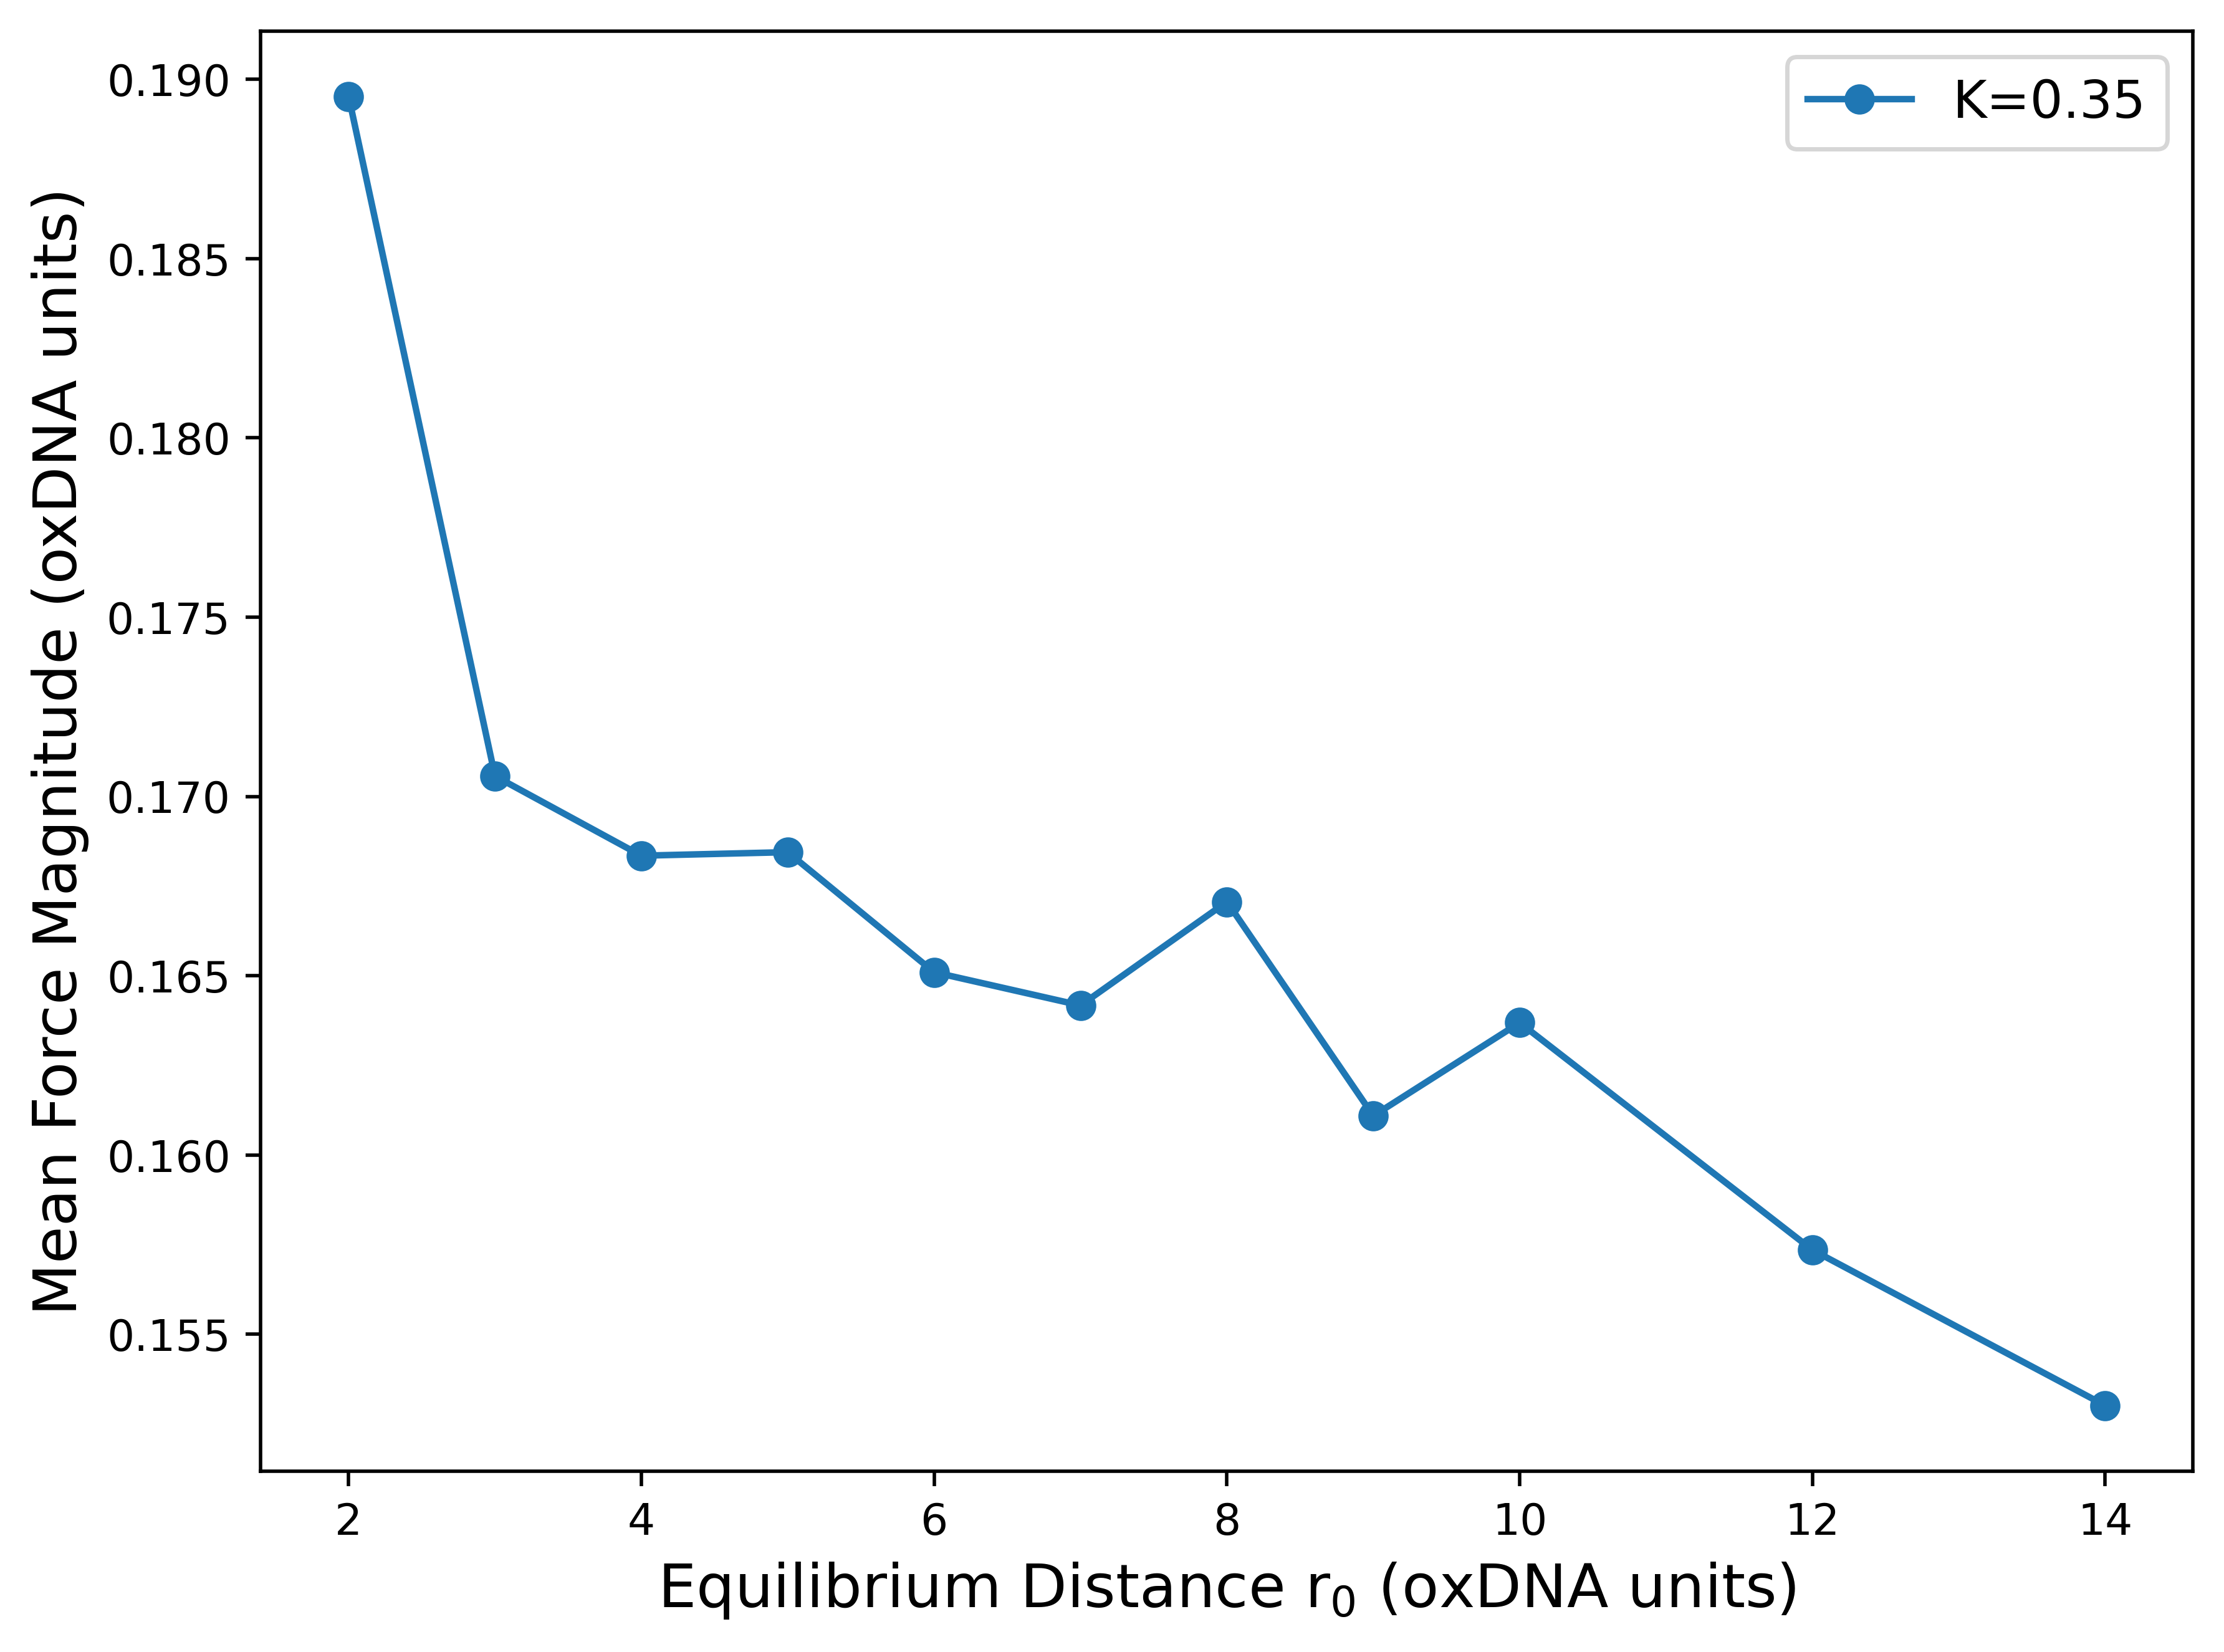

In [51]:
####  PLOT OF FORCE MEANS VS R0
fig, ax = plt.subplots(figsize=(8,6), dpi=500)
ax.plot(K35_stats_df['r_0'], 
        K35_stats_df['|F| mean'],
        marker='o', label='K=0.35')
ax.set_xlabel('Equilibrium Distance r$_0$ (oxDNA units)', fontsize=14)
ax.set_ylabel('Mean Force Magnitude (oxDNA units)', fontsize=14)
ax.legend(fontsize=12)
fig.show()

C:\Users\Tristan\AppData\Local\Temp\ipykernel_32868\1808976682.py:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


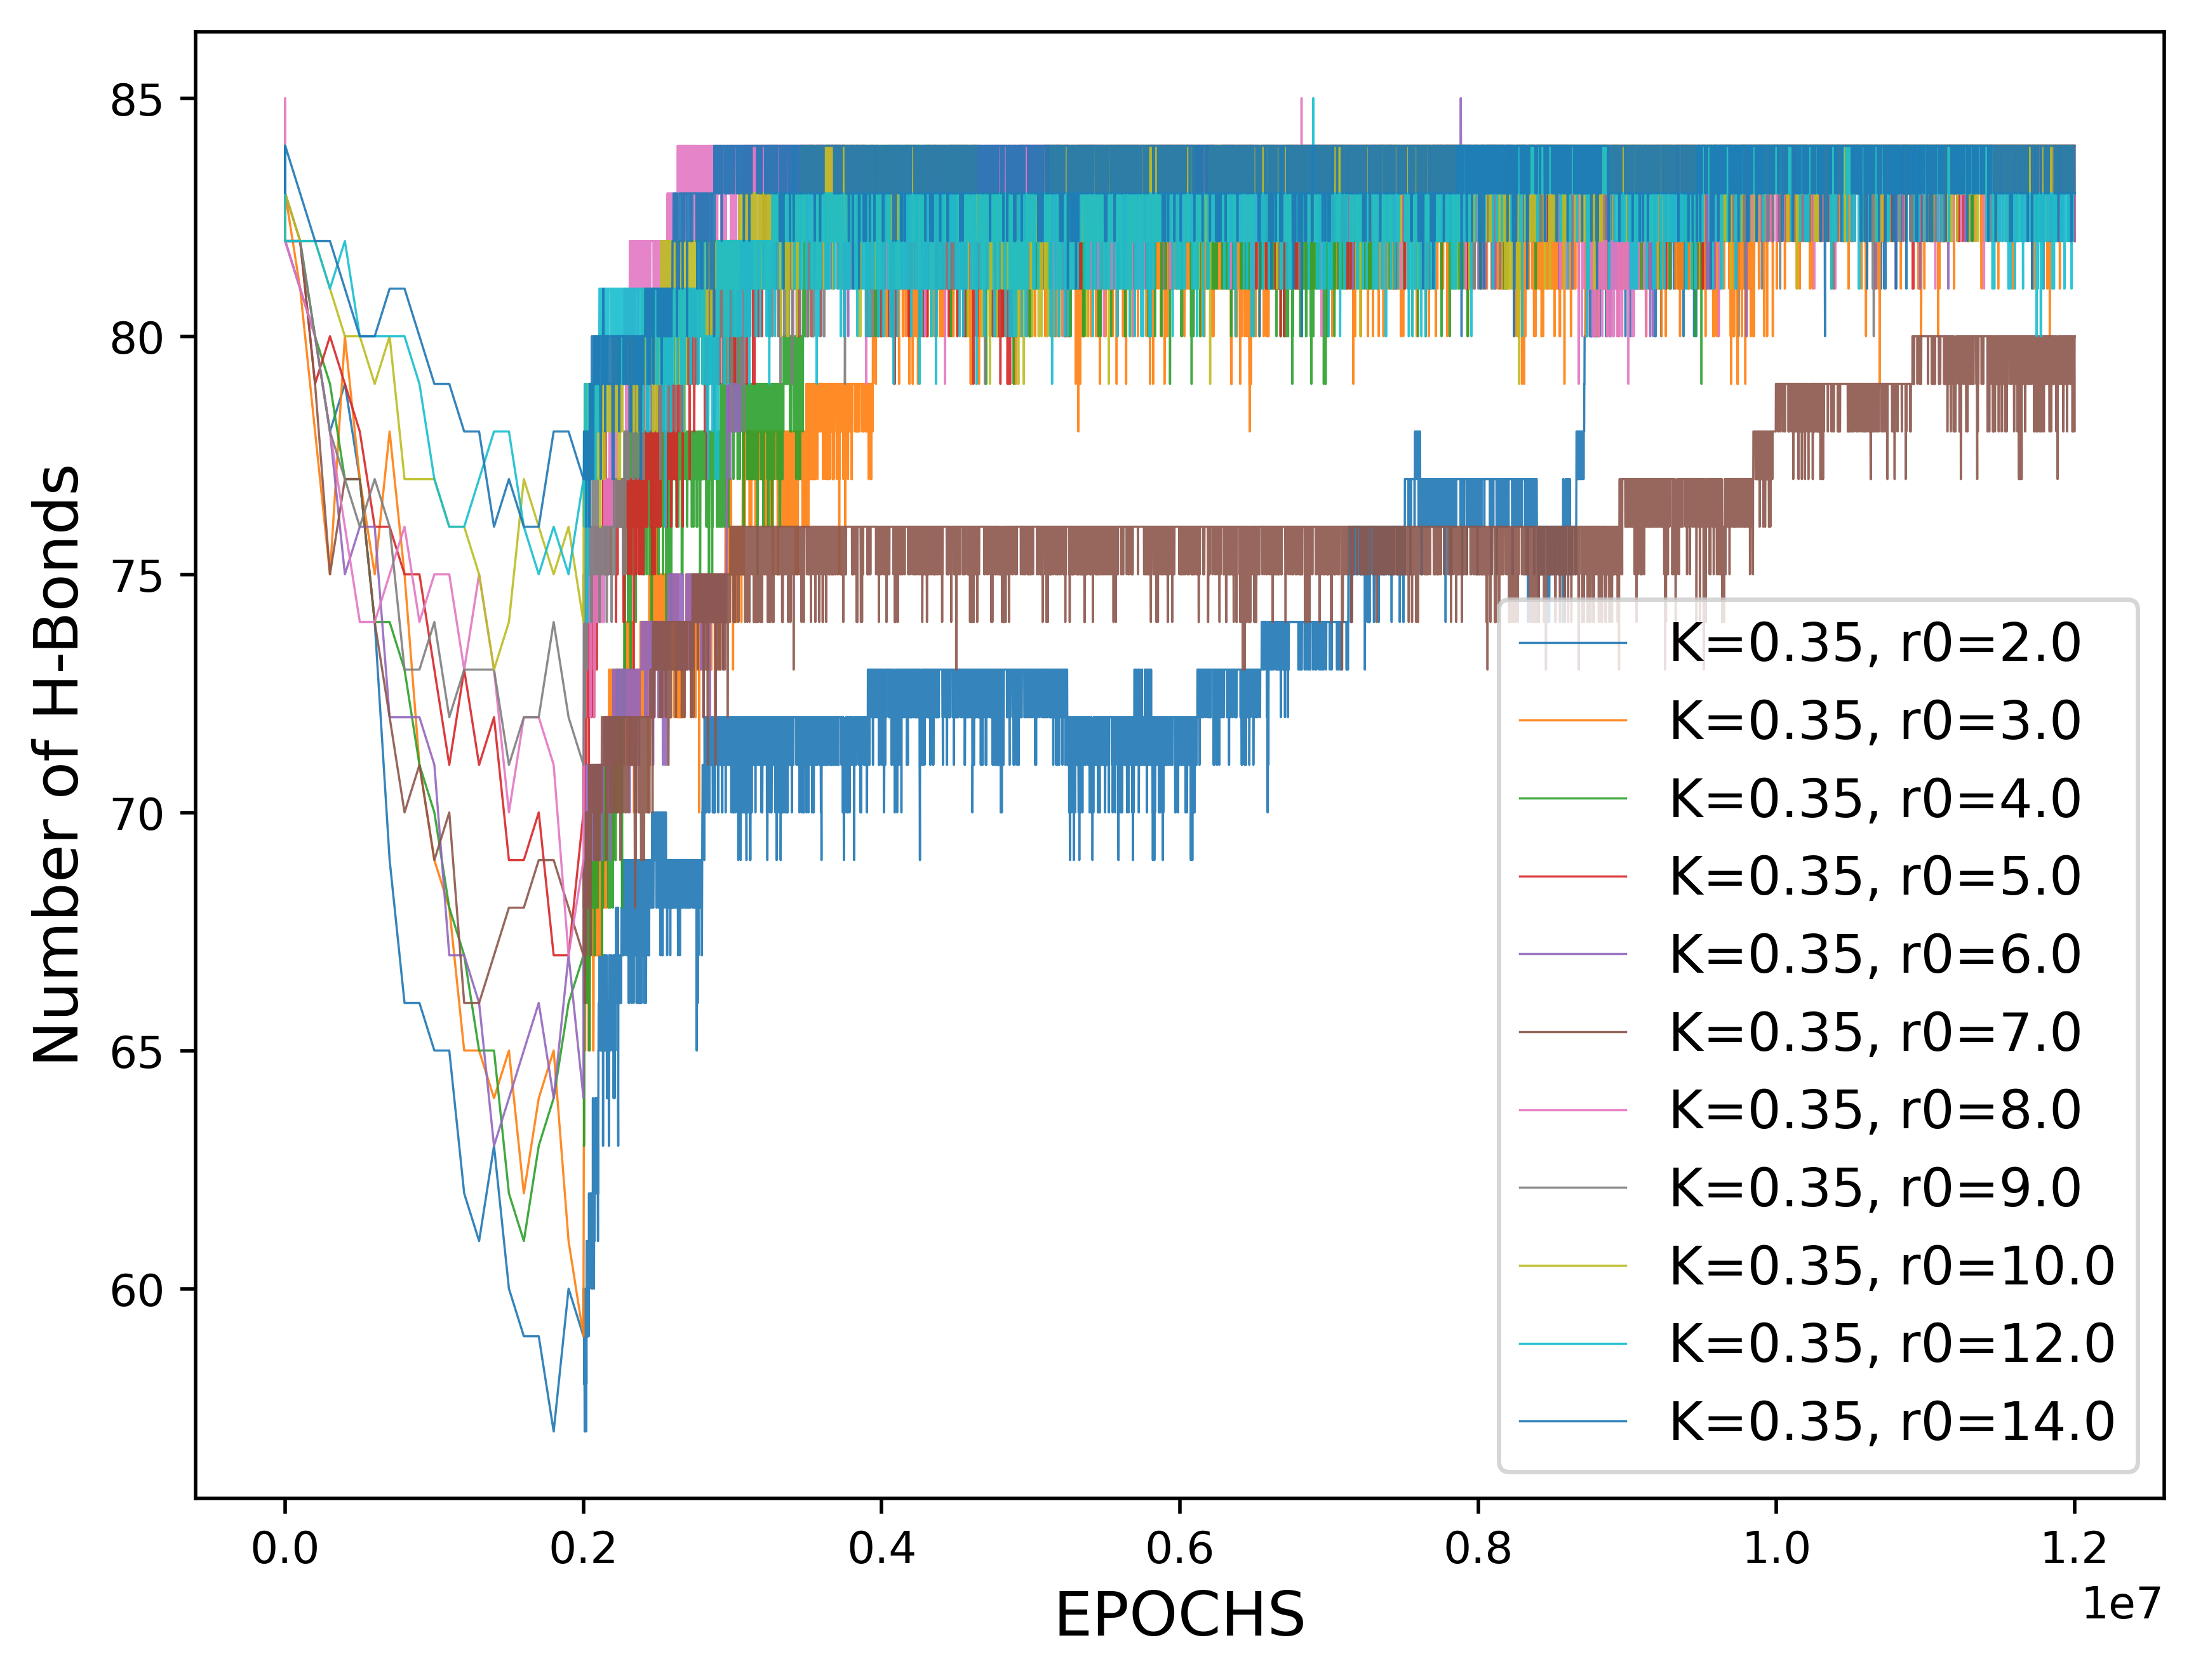

In [52]:
#### PLOT OF HBONDS VS TIME
fig, ax = plt.subplots(figsize=(8,6), dpi=500)

# Map r0 values to their corresponding filtered dataframes
df_filtered_dict = {
    2: K35_r0_2_df_filtered,
    3: K35_r0_3_df_filtered,
    4: K35_r0_4_df_filtered,
    5: K35_r0_5_df_filtered,
    6: K35_r0_6_df_filtered,
    7: K35_r0_7_df_filtered,
    8: K35_r0_8_df_filtered,
    9: K35_r0_9_df_filtered,
    10: K35_r0_10_df_filtered,
    12: K35_r0_12_df_filtered,
    14: K35_r0_14_df_filtered
}

# Plot each series from the stats dataframe
for idx, row in K35_stats_df.iterrows():
    r0 = int(float(row['r_0']))
    df = df_filtered_dict[r0]
    ax.plot(df['step'], df['hbond'],
            alpha=0.9, linewidth=0.5, 
            label=f'K=0.35, r0={row["r_0"]}')

ax.set_xlabel('EPOCHS', fontsize=14)
ax.set_ylabel('Number of H-Bonds', fontsize=14)
ax.legend(fontsize=12)
fig.show()